In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [43]:
df_all = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/all0818_2_alltruth.csv')

In [40]:
df_all.shape[0]

6558306

In [4]:
df_all.columns

Index(['pt', 'b', 'w', 'reject', 'pt1', 'pt2', 'y1', 'y2', 'phi1', 'phi2',
       'nef', 'evid', 'pts', 'bs', 'ws', 'rejects', 'pt1s', 'pt2s', 'y1s',
       'y2s', 'phi1s', 'phi2s', 'nefs', 'evids', 'distance1', 'distance2'],
      dtype='object')

In [28]:
df_alltruth = applyCut(df_all, 'pt>5 and b!=-9 and nef<0.9')

In [29]:
df_match = applyCut(df_alltruth, 'pts>15 and bs!=-9 and distance1<0.02 and distance2<0.02')

In [30]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)],\
                       df_alltruth[(df_alltruth.pt>40) & (df_alltruth.pt<60)]  ]

In [31]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [32]:
rc_alltruth_b_vs_pt_array = []
rc_err_alltruth_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    rc_err_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

In [33]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

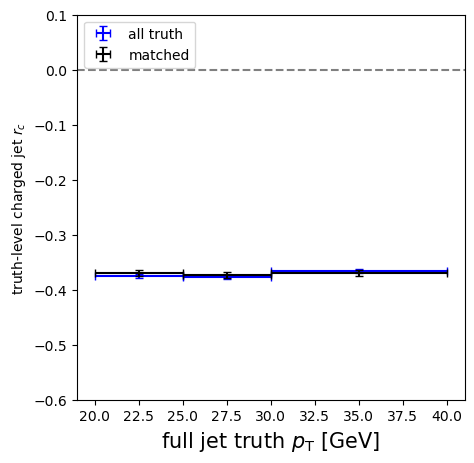

In [34]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:-1], capsize=3, color='b', ls='none', label='all truth')
plt.errorbar([22.5, 27.5, 35], rc_match_b_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_vs_pt_array[1:-1], capsize=3, color='k', ls='none', label='matched')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('truth-level charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [35]:
def get_eff2(df):
    true = np.histogram(df['pt'], bins=binedges, weights=df['w'])[0]
    match = np.histogram(df[df.pts>15]['pt'], bins=binedges, weights=df[df.pts>15]['w'])[0]
    return match/true

In [36]:
def get_eff3(df):
    true = np.histogram(df['pt'], bins=binedges, weights=df['w'])[0]
    match = np.histogram(df[(df.pts>15) & (df.bs!=-9)]['pt'], bins=binedges, weights=df[(df.pts>15) & (df.bs!=-9)]['w'])[0]
    return match/true

In [37]:
def get_eff4(df):
    true = np.histogram(df['pt'], bins=binedges, weights=df['w'])[0]
    match = np.histogram(df[(df.pts>15) & (df.bs!=-9) & (df.distance1<0.02) & (df.distance2<0.02)]['pt'], bins=binedges, weights=df[(df.pts>15) & (df.bs!=-9) & (df.distance1<0.02) & (df.distance2<0.02)]['w'])[0]
    return match/true

In [38]:
df_os = applyCut(df_alltruth, 'b==-1')
df_ss = applyCut(df_alltruth, 'b==1')

[2.55609925e-05 1.16558103e-02 2.92035668e-01 6.10750373e-01
 7.52328584e-01 8.28768868e-01 8.39665706e-01]
[2.38349977e-05 1.09369801e-02 2.89972686e-01 6.25643996e-01
 7.71752901e-01 8.44255390e-01 8.55055808e-01]
[4.26223354e-06 9.37733827e-03 2.32817495e-01 4.41368535e-01
 5.17752109e-01 5.58079597e-01 5.29085600e-01]
[2.92671028e-06 8.80377238e-03 2.26738551e-01 4.47204686e-01
 5.22322993e-01 5.53103281e-01 5.21613005e-01]


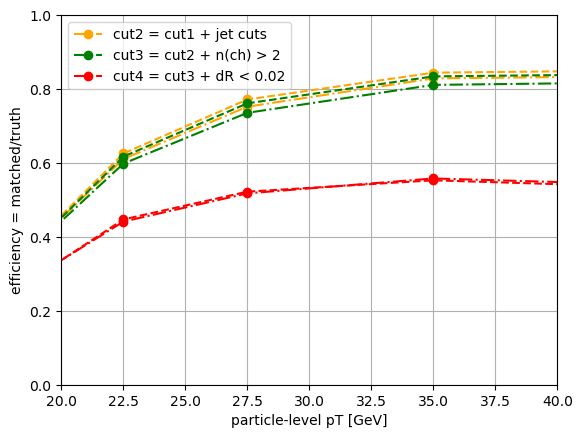

In [39]:
x=[7.5,12.5,17.5,22.5,27.5,35,50]
binedges=[5,10,15,20,25,30,40,60]
plt.plot(x, get_eff2(df_os), 'o-.', color='orange', label='cut2 = cut1 + jet cuts')
plt.plot(x, get_eff3(df_os), 'o-.', color='g', label='cut3 = cut2 + n(ch) > 2')
plt.plot(x, get_eff4(df_os), 'o-.', color='r', label='cut4 = cut3 + dR < 0.02')
plt.plot(x, get_eff2(df_ss), 'o--', color='orange')#, label='cut2 = cut1 + jet cuts')
plt.plot(x, get_eff3(df_ss), 'o--', color='g')#, label='cut3 = cut2 + n(ch) > 2')
plt.plot(x, get_eff4(df_ss), 'o--', color='r')#, label='cut4 = cut3 + dR < 0.02')
plt.xlabel('particle-level pT [GeV]')
plt.ylabel('efficiency = matched/truth')
plt.legend()
plt.grid()
plt.xlim(20,40)
plt.ylim(0.,1)
#plt.title('truth-level opposite pairs')
print(get_eff4(df_os))
print(get_eff4(df_ss))